# Тема 4. Парадоксы в теории вероятностей
> Рассмотреть какой-нибудь парадокс. Смоделировать его решение в Python.

## Парадокс двух конвертов
https://ru.wikipedia.org/wiki/Задача_о_двух_конвертах

Есть два неразличимых конверта с деньгами. В одном находится сумма в два раза большая, чем во втором. Величина этой суммы неизвестна. Конверты дают двум игрокам. Каждый из них может открыть свой конверт и пересчитать в нём деньги. После этого игроки должны решить: стоит ли обменять свой конверт на чужой?
Оба игрока рассуждают следующим образом. Я вижу в своём конверте сумму $X$. В чужом конверте равновероятно может находиться $2X$ или $\frac{X}{2}$. Поэтому если я поменяю конверт, то у меня в среднем будет $\frac{(2X+\frac{X}{2})}{2} = \frac{5}{4}X$, то есть больше, чем сейчас. Значит, обмен выгоден. Однако обмен не может быть выгоден обоим игрокам. Где в их рассуждениях кроется ошибка?

Ошибка рассуждения в том, что $X$ обозначает разные величины в двух слагаемых: в первом случае $X$ — меньшая сумма, во втором — большая.

**Задача**. Определить вероятность того, что игрок уйдёт с **большей** суммой, при двух стратегиях: **оставить** выбранный конверт и **поменять** его.

Обозначим суммы в конвертах через $A$ и $2A$. Игрок берёт любой конверт с вероятностью $\frac{1}{2}$.

Если игрок **оставляет** конверт, он уходит с большей суммой, только если сразу взял больший конверт:

$$P(\text{оставить}) = \frac{1}{2}.$$

Если игрок **меняет** конверт, он уходит с большей суммой, только если сначала взял меньший конверт:

$$P(\text{поменять}) = \frac{1}{2}.$$

Если игрок меняет конверт $k$ раз подряд, он уходит с большей суммой с вероятностью $\frac{1}{2}$ при любом $k$: каждый обмен просто переводит его на другой конверт.

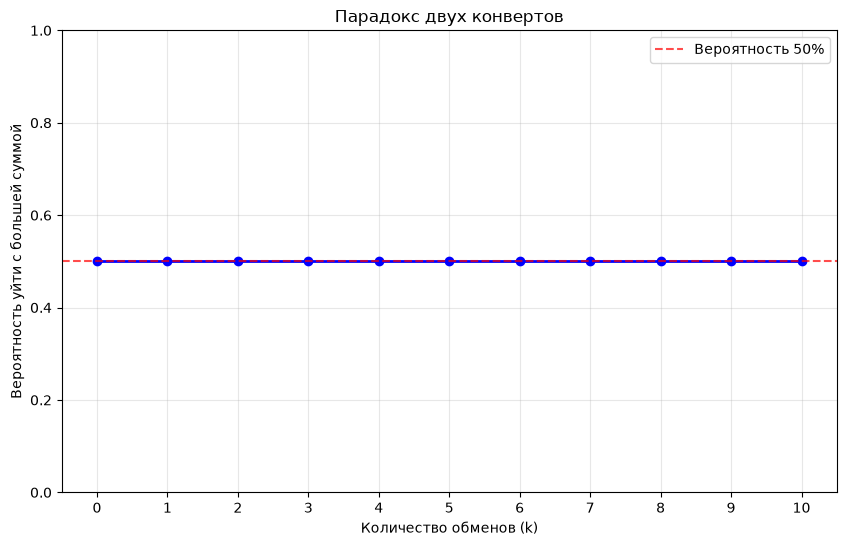

P(оставить) = 0.500, P(поменять) = 0.500


In [17]:
import numpy as np
import matplotlib.pyplot as plt

def probability_larger(k):
    """Вероятность уйти с большей суммой, если поменять конверт k раз"""
    # Начальный выбор: больший конверт с вероятностью 1/2.
    # При чётном k игрок остаётся с исходным конвертом, при нечётном — с другим.
    p_first_larger = 1 / 2
    return p_first_larger if k % 2 == 0 else 1 - p_first_larger

k_values = np.arange(0, 11)
probabilities = [probability_larger(k) for k in k_values]

plt.figure(figsize=(10, 6))
plt.plot(k_values, probabilities, 'b-o', linewidth=2)
plt.xlabel('Количество обменов (k)')
plt.ylabel('Вероятность уйти с большей суммой')
plt.title('Парадокс двух конвертов')
plt.ylim(0, 1)
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.7, label='Вероятность 50%')
plt.legend()
plt.show()

print(f"P(оставить) = {probability_larger(0):.3f}, P(поменять) = {probability_larger(1):.3f}")

### Моделирование в Pandas

In [18]:
import pandas as pd

A = 100
envelopes = pd.Series([A, 2 * A])

Проведем одну игру.

In [19]:
choice = envelopes.sample(1)                    # выбранный конверт
other = envelopes.drop(choice.index).item()     # другой конверт
choice = choice.item()

print(f"В выбранном конверте: {choice}")
print(f"В другом конверте: {other}")
print(f"Если оставить — большая сумма: {choice == 2 * A}")
print(f"Если поменять — большая сумма: {other == 2 * A}")

В выбранном конверте: 200
В другом конверте: 100
Если оставить — большая сумма: True
Если поменять — большая сумма: False


Оформим одну игру в виде функции.

In [20]:
def two_envelopes(A=100, change=True):
    """Одна игра: возвращает True, если игрок ушёл с большей суммой"""
    envelopes = pd.Series([A, 2 * A])
    choice = envelopes.sample(1)
    other = envelopes.drop(choice.index).item()
    result = other if change else choice.item()
    return result == 2 * A

Проведем серию из 10000 испытаний для каждой стратегии (оставить конверт/поменять).

In [21]:
stay = [two_envelopes(100, change=False) for _ in range(10_000)]
change = [two_envelopes(100, change=True) for _ in range(10_000)]

Частота события, когда игрок ушел с большей суммой

In [22]:
print(f"Частота, если оставить: {np.mean(stay):.4f}")
print(f"Частота, если поменять: {np.mean(change):.4f}")

Частота, если оставить: 0.5088
Частота, если поменять: 0.4968


**Вывод**. Результаты моделирования совпадают с теоретическими: при обеих стратегиях игрок уходит с большей суммой примерно в половине случаев. Обмен конверта не даёт никакого преимущества.